In [1]:
import pandas as pd
import numpy as np
import re

In [2]:
# Load the raw training dataset
df = pd.read_csv("training_data_202601.csv")

# Make a copy so the original raw dataframe stays unchanged
df_clean = df.copy()

In [3]:
# Check types
print("Column types:\n")
for col in df_clean.columns:
    print(f"{col}: {df_clean[col].dtype}")

Column types:

unique_id: int64
Painting: object
On a scale of 1–10, how intense is the emotion conveyed by the artwork?: float64
Describe how this painting makes you feel.: object
This art piece makes me feel sombre.: object
This art piece makes me feel content.: object
This art piece makes me feel calm.: object
This art piece makes me feel uneasy.: object
How many prominent colours do you notice in this painting?: float64
How many objects caught your eye in the painting?: float64
How much (in Canadian dollars) would you be willing to pay for this painting?: object
If you could purchase this painting, which room would you put that painting in?: object
If you could view this art in person, who would you want to view it with?: object
What season does this art piece remind you of?: object
If this painting was a food, what would be?: object
Imagine a soundtrack for this painting. Describe that soundtrack without naming any objects in the painting.: object


In [4]:
# Target and identifier columns
target_col = "Painting"
id_col = "unique_id"

# Numeric columns
numeric_cols = [
    "On a scale of 1–10, how intense is the emotion conveyed by the artwork?",
    "How many prominent colours do you notice in this painting?",
    "How many objects caught your eye in the painting?"
]

# Likert-style columns such as "1 - Strongly disagree", "5 - Strongly agree"
likert_cols = [
    "This art piece makes me feel sombre.",
    "This art piece makes me feel content.",
    "This art piece makes me feel calm.",
    "This art piece makes me feel uneasy."
]

# Money column with messy free-form responses
money_col = "How much (in Canadian dollars) would you be willing to pay for this painting?"

# multi-select categorical columns
multi_select_cols = [
    "If you could purchase this painting, which room would you put that painting in?",
    "If you could view this art in person, who would you want to view it with?",
    "What season does this art piece remind you of?"
]

# Free-text columns
text_cols = [
    "Describe how this painting makes you feel.",
    "If this painting was a food, what would be?",
    "Imagine a soundtrack for this painting. Describe that soundtrack without naming any objects in the painting."
]

In [5]:
# Strip whitespace for string values
for col in df_clean.columns:
    if df_clean[col].dtype == "object":
        df_clean[col] = df_clean[col].apply(
            lambda x: x.strip() if isinstance(x, str) else x
        )

In [6]:
# Inspect class labels
print(df_clean[target_col].value_counts(dropna=False))
print("\nUnique labels:")
print(sorted(df_clean[target_col].dropna().unique()))

Painting
The Persistence of Memory    562
The Starry Night             562
The Water Lily Pond          562
Name: count, dtype: int64

Unique labels:
['The Persistence of Memory', 'The Starry Night', 'The Water Lily Pond']


In [7]:
# Clean the Likert columns
# Extract the leading number from a Likert-style response
def extract_rating(x):
    if pd.isna(x):
        return np.nan

    match = re.match(r"^\s*(\d+)", str(x))
    if match:
        return float(match.group(1))
    return np.nan

# Apply to each Likert column
for col in likert_cols:
    df_clean[col] = df_clean[col].apply(extract_rating)

# Check results
for col in likert_cols:
    print(f"\n{col}")
    print(df_clean[col].value_counts(dropna=False).sort_index())


This art piece makes me feel sombre.
This art piece makes me feel sombre.
1.0    414
2.0    347
3.0    207
4.0    483
5.0    165
NaN     70
Name: count, dtype: int64

This art piece makes me feel content.
This art piece makes me feel content.
1.0    136
2.0    361
3.0    236
4.0    507
5.0    374
NaN     72
Name: count, dtype: int64

This art piece makes me feel calm.
This art piece makes me feel calm.
1.0     81
2.0    279
3.0    232
4.0    519
5.0    504
NaN     71
Name: count, dtype: int64

This art piece makes me feel uneasy.
This art piece makes me feel uneasy.
1.0    572
2.0    401
3.0    137
4.0    364
5.0    141
NaN     71
Name: count, dtype: int64


In [8]:
# Clean the free-text columns
# Basic text cleaning: lowercase, trim, collapse repeated spaces
def clean_text(x):
    if pd.isna(x):
        return ""

    s = str(x).lower().strip()
    s = re.sub(r"\s+", " ", s)
    return s

# Apply to each text column
for col in text_cols:
    df_clean[col] = df_clean[col].apply(clean_text)

# Show a few cleaned examples
for col in text_cols:
    print(f"\nSample cleaned values from: {col}")
    print(df_clean[col].head(3).tolist())


Sample cleaned values from: Describe how this painting makes you feel.
['', 'the clocks are burnt on a hot desert, it embodies the melancholy of time passing. the dominant yellow hue intensifies this sensation.', 'this painting makes me feel dread. the clock reminds me of a ticking time until the death of the creature in the picture.']

Sample cleaned values from: If this painting was a food, what would be?
['', 'fries', 'sardines']

Sample cleaned values from: Imagine a soundtrack for this painting. Describe that soundtrack without naming any objects in the painting.
['', 'a country song that contrasts nostalgia for the past with dissatisfaction with the present.', 'a melancholy instrumental with a monotone voice singing gloomy lyrics like creep by radiohead.']


In [9]:
# Clean the multi-select categorical columns
# Standardize multi-select categorical responses
def clean_multiselect(x):
    if pd.isna(x):
        return np.nan

    s = str(x).lower().strip()

    # Normalize separators
    s = s.replace(";", ",")
    s = s.replace("|", ",")
    s = s.replace("/", ",")

    # Split into items, trim spaces, remove empty items
    parts = [p.strip() for p in s.split(",") if p.strip()]

    # Sort so equivalent answers become identical
    parts = sorted(parts)

    if len(parts) == 0:
        return np.nan

    return ",".join(parts)

# Apply to each multi-select column
for col in multi_select_cols:
    df_clean[col] = df_clean[col].apply(clean_multiselect)

# Check common values
for col in multi_select_cols:
    print(f"\n{col}")
    print(df_clean[col].value_counts(dropna=False).head(10))


If you could purchase this painting, which room would you put that painting in?
If you could purchase this painting, which room would you put that painting in?
living room                                        207
office                                             201
bedroom                                            181
bathroom                                           159
bedroom,living room                                 94
living room,office                                  84
NaN                                                 80
dining room,living room                             73
bathroom,bedroom,dining room,living room,office     70
bedroom,dining room,living room                     70
Name: count, dtype: int64

If you could view this art in person, who would you want to view it with?
If you could view this art in person, who would you want to view it with?
by yourself                                                          335
by yourself,family members,friends       

In [10]:
# Clean the money column
def parse_money(x):
    """
    Convert willingness-to-pay text into a numeric value.

    Rules:
    - Missing -> NaN
    - Remove common currency text/symbols
    - Range like '200-300' -> midpoint 250
    - Shorthand like '1k' -> 1000
    - True negatives like '-50' are kept for now, so we can clean them explicitly later
    """
    if pd.isna(x):
        return np.nan

    s = str(x).lower().strip()
    s = s.replace("$", "")
    s = s.replace(",", "")
    s = s.replace("cad", "")
    s = s.replace("dollars", "")
    s = s.replace("dollar", "")
    s = re.sub(r"\s+", " ", s)

    # Case 1: numeric range like 200-300 or 1k-2k
    range_match = re.search(r'(\d*\.?\d+)\s*(k?)\s*-\s*(\d*\.?\d+)\s*(k?)', s)
    if range_match:
        a = float(range_match.group(1))
        b = float(range_match.group(3))

        if range_match.group(2) == "k":
            a *= 1000
        if range_match.group(4) == "k":
            b *= 1000

        return (a + b) / 2

    # Case 2: single number, optionally negative, optionally with k
    single_match = re.search(r'(?<!\w)(-?\d*\.?\d+)\s*(k?)', s)
    if single_match:
        val = float(single_match.group(1))
        if single_match.group(2) == "k":
            val *= 1000
        return val

    return np.nan

money_col = "How much (in Canadian dollars) would you be willing to pay for this painting?"

df_clean[money_col] = df_clean[money_col].apply(parse_money)
print(df_clean[money_col].describe())
print("\nNegative parsed values:")
print(df_clean[df_clean[money_col] < 0][["unique_id", "Painting", money_col]])

count    1.598000e+03
mean     6.257829e+26
std      2.501564e+28
min     -1.000000e+02
25%      3.500000e+01
50%      1.000000e+02
75%      1.000000e+03
max      1.000000e+30
Name: How much (in Canadian dollars) would you be willing to pay for this painting?, dtype: float64

Negative parsed values:
      unique_id                   Painting  \
875         434  The Persistence of Memory   
990         549  The Persistence of Memory   
1331        549           The Starry Night   

      How much (in Canadian dollars) would you be willing to pay for this painting?  
875                                               -10.0                              
990                                               -50.0                              
1331                                             -100.0                              


In [11]:
# Check types after cleaning
print("Column types after cleaning:\n")
for col in df_clean.columns:
    print(f"{col}: {df_clean[col].dtype}")

# Check missing values
print("\nMissing values after cleaning:")
print(df_clean.isna().sum().sort_values(ascending=False))

Column types after cleaning:

unique_id: int64
Painting: object
On a scale of 1–10, how intense is the emotion conveyed by the artwork?: float64
Describe how this painting makes you feel.: object
This art piece makes me feel sombre.: float64
This art piece makes me feel content.: float64
This art piece makes me feel calm.: float64
This art piece makes me feel uneasy.: float64
How many prominent colours do you notice in this painting?: float64
How many objects caught your eye in the painting?: float64
How much (in Canadian dollars) would you be willing to pay for this painting?: float64
If you could purchase this painting, which room would you put that painting in?: object
If you could view this art in person, who would you want to view it with?: object
What season does this art piece remind you of?: object
If this painting was a food, what would be?: object
Imagine a soundtrack for this painting. Describe that soundtrack without naming any objects in the painting.: object

Missing valu

In [12]:
# Save cleaned dataset for later modeling
df_clean.to_csv("clean_dataset.csv", index=False)

print("Saved clean_dataset.csv")

Saved clean_dataset.csv


In [13]:
from sklearn.model_selection import train_test_split, StratifiedKFold

# First split off the 20% test set
# This test set will stay untouched until the very end
trainval_df, test_df = train_test_split(
    df_clean,
    test_size=0.20,
    stratify=df_clean["Painting"],
    random_state=42
)

# Set up 5-fold stratified cross-validation on the remaining 80%
# This replaces the old single validation split
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Check sizes
print("Train+CV shape:", trainval_df.shape)
print("Test shape:", test_df.shape)

# Check class distributions
print("\nTrain+CV class distribution:")
print(trainval_df["Painting"].value_counts(normalize=True))

print("\nTest class distribution:")
print(test_df["Painting"].value_counts(normalize=True))

Train+CV shape: (1348, 16)
Test shape: (338, 16)

Train+CV class distribution:
Painting
The Persistence of Memory    0.333828
The Starry Night             0.333086
The Water Lily Pond          0.333086
Name: proportion, dtype: float64

Test class distribution:
Painting
The Water Lily Pond          0.334320
The Starry Night             0.334320
The Persistence of Memory    0.331361
Name: proportion, dtype: float64


In [14]:
# Make copies so the original split data stays untouched
trainval_copy = trainval_df.copy()
test_copy = test_df.copy()

In [15]:
# Update Numeric columns(include the money column now)
numeric_cols = [
    "On a scale of 1–10, how intense is the emotion conveyed by the artwork?",
    "How many prominent colours do you notice in this painting?",
    "How many objects caught your eye in the painting?",
    "How much (in Canadian dollars) would you be willing to pay for this painting?"
]

In [16]:
# Numeric imputation
# Learn numeric medians from the train+CV set only
numeric_medians = trainval_copy[numeric_cols].median()

print("Numeric medians learned from train+CV set:")
print(numeric_medians)

# Apply the same train+CV medians to both sets
trainval_copy[numeric_cols] = trainval_copy[numeric_cols].fillna(numeric_medians)
test_copy[numeric_cols] = test_copy[numeric_cols].fillna(numeric_medians)

Numeric medians learned from train+CV set:
On a scale of 1–10, how intense is the emotion conveyed by the artwork?            7.0
How many prominent colours do you notice in this painting?                         3.0
How many objects caught your eye in the painting?                                  3.0
How much (in Canadian dollars) would you be willing to pay for this painting?    100.0
dtype: float64


In [17]:
# Likert imputation
# Learn the mode of each Likert column from the train+CV set only
# mode().iloc[0] takes the most frequent value for each column
likert_modes = trainval_copy[likert_cols].mode().iloc[0]

print("Likert modes learned from train+CV set:")
print(likert_modes)

# Apply the same train+CV modes to both sets
trainval_copy[likert_cols] = trainval_copy[likert_cols].fillna(likert_modes)
test_copy[likert_cols] = test_copy[likert_cols].fillna(likert_modes)

# Store them as integer-like values
for col in likert_cols:
    trainval_copy[col] = trainval_copy[col].astype("Int64")
    test_copy[col] = test_copy[col].astype("Int64")

Likert modes learned from train+CV set:
This art piece makes me feel sombre.     4.0
This art piece makes me feel content.    4.0
This art piece makes me feel calm.       4.0
This art piece makes me feel uneasy.     1.0
Name: 0, dtype: float64


In [18]:
# Categorical filling
# Treat missing categorical values as an explicit category
for col in multi_select_cols:
    trainval_copy[col] = trainval_copy[col].fillna("No Answer")
    test_copy[col] = test_copy[col].fillna("No Answer")

In [19]:
# Text filling
# Fill missing text responses with empty strings
for col in text_cols:
    trainval_copy[col] = trainval_copy[col].fillna("")
    test_copy[col] = test_copy[col].fillna("")

In [20]:
# Columns that are right-skewed
log_cols = [
    "How many prominent colours do you notice in this painting?",
    "How many objects caught your eye in the painting?",
    "How much (in Canadian dollars) would you be willing to pay for this painting?"
]

# Clip invalid negative values before log transform
for col in log_cols:
    trainval_copy[col] = trainval_copy[col].clip(lower=0)
    test_copy[col] = test_copy[col].clip(lower=0)

# Apply log1p transformation to the train+CV set and the test set
for col in log_cols:
    trainval_copy[col] = np.log1p(trainval_copy[col])
    test_copy[col] = np.log1p(test_copy[col])

print("Applied log1p transformation to skewed numeric columns.")

Applied log1p transformation to skewed numeric columns.


In [21]:
# Combine the 3 short text columns into one text field
def combine_text_columns(df):
    return (
        df["Describe how this painting makes you feel."].astype(str) + " " +
        df["If this painting was a food, what would be?"].astype(str) + " " +
        df["Imagine a soundtrack for this painting. Describe that soundtrack without naming any objects in the painting."].astype(str)
    )

trainval_copy["combined_text"] = combine_text_columns(trainval_copy)
test_copy["combined_text"] = combine_text_columns(test_copy)

In [22]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder

# Build text and categorical features with training data only
# This function will be used inside each CV fold to avoid leakage
def build_text_cat_features(train_df, valid_df, test_df=None):
    # Create a TF-IDF vectorizer
    tfidf = TfidfVectorizer(max_features=500, ngram_range=(1, 2))

    # Learn vocabulary from fold-training text only
    X_train_text = tfidf.fit_transform(train_df["combined_text"])
    X_valid_text = tfidf.transform(valid_df["combined_text"])

    if test_df is not None:
        X_test_text = tfidf.transform(test_df["combined_text"])
    else:
        X_test_text = None

    print("Train text matrix shape:", X_train_text.shape)
    print("Validation text matrix shape:", X_valid_text.shape)
    if X_test_text is not None:
        print("Test text matrix shape:", X_test_text.shape)

    # Convert categorical string responses into numeric indicator columns
    # Fit on training data only to avoid leakage
    try:
        ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=True)
    except TypeError:
        ohe = OneHotEncoder(handle_unknown="ignore", sparse=True)

    X_train_cat = ohe.fit_transform(train_df[multi_select_cols])
    X_valid_cat = ohe.transform(valid_df[multi_select_cols])

    if test_df is not None:
        X_test_cat = ohe.transform(test_df[multi_select_cols])
    else:
        X_test_cat = None

    print("\nCategorical feature shapes:")
    print("X_train_cat:", X_train_cat.shape)
    print("X_valid_cat:", X_valid_cat.shape)
    if X_test_cat is not None:
        print("X_test_cat:", X_test_cat.shape)

    return tfidf, ohe, X_train_text, X_valid_text, X_test_text, X_train_cat, X_valid_cat, X_test_cat

In [23]:
from scipy.sparse import hstack, csr_matrix

# Keep numeric and ordinal features as direct inputs,
# then combine numeric + categorical + text features.
# This function will be used inside each CV fold.
def build_full_feature_matrices(train_df, valid_df, X_train_cat, X_valid_cat, X_train_text, X_valid_text, test_df=None, X_test_cat=None, X_test_text=None):
    base_numeric_cols = numeric_cols + likert_cols

    X_train_num = train_df[base_numeric_cols].astype(float).values
    X_valid_num = valid_df[base_numeric_cols].astype(float).values

    print("\nNumeric feature shapes:")
    print("X_train_num:", X_train_num.shape)
    print("X_valid_num:", X_valid_num.shape)

    X_train = hstack([csr_matrix(X_train_num), X_train_cat, X_train_text])
    X_valid = hstack([csr_matrix(X_valid_num), X_valid_cat, X_valid_text])

    print("\nFinal feature matrix shapes:")
    print("X_train:", X_train.shape)
    print("X_valid:", X_valid.shape)

    if test_df is not None:
        X_test_num = test_df[base_numeric_cols].astype(float).values
        print("X_test_num:", X_test_num.shape)

        X_test = hstack([csr_matrix(X_test_num), X_test_cat, X_test_text])
        print("X_test:", X_test.shape)

        return X_train, X_valid, X_test

    return X_train, X_valid

In [24]:
# Target arrays
y_trainval = trainval_copy["Painting"].values
y_test = test_copy["Painting"].values

print("y_trainval:", y_trainval.shape)
print("y_test:", y_test.shape)

y_trainval: (1348,)
y_test: (338,)


In [25]:
# Random Forest model
from sklearn.ensemble import RandomForestClassifier

# Evaluation metrics
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# Saving artifacts
import os
import joblib

# For the bias-variance plot
import matplotlib.pyplot as plt

In [26]:
# Create a folder for saved model artifacts
os.makedirs("artifacts", exist_ok=True)

In [27]:
# =========================================================
# 1. Hyperparameter grid for Random Forest
# =========================================================
rf_param_grid = [
    {"n_estimators": 100, "max_depth": 10, "ccp_alpha": 0.0},
    {"n_estimators": 100, "max_depth": 10, "ccp_alpha": 0.0005},
    {"n_estimators": 100, "max_depth": 10, "ccp_alpha": 0.001},
    {"n_estimators": 100, "max_depth": 10, "ccp_alpha": 0.005},
    {"n_estimators": 100, "max_depth": 10, "ccp_alpha": 0.01},

    {"n_estimators": 100, "max_depth": 20, "ccp_alpha": 0.0},
    {"n_estimators": 100, "max_depth": 20, "ccp_alpha": 0.0005},
    {"n_estimators": 100, "max_depth": 20, "ccp_alpha": 0.001},
    {"n_estimators": 100, "max_depth": 20, "ccp_alpha": 0.005},
    {"n_estimators": 100, "max_depth": 20, "ccp_alpha": 0.01},

    {"n_estimators": 100, "max_depth": None, "ccp_alpha": 0.0},
    {"n_estimators": 100, "max_depth": None, "ccp_alpha": 0.0005},
    {"n_estimators": 100, "max_depth": None, "ccp_alpha": 0.001},
    {"n_estimators": 100, "max_depth": None, "ccp_alpha": 0.005},
    {"n_estimators": 100, "max_depth": None, "ccp_alpha": 0.01},

    {"n_estimators": 200, "max_depth": 10, "ccp_alpha": 0.0},
    {"n_estimators": 200, "max_depth": 10, "ccp_alpha": 0.0005},
    {"n_estimators": 200, "max_depth": 10, "ccp_alpha": 0.001},
    {"n_estimators": 200, "max_depth": 10, "ccp_alpha": 0.005},
    {"n_estimators": 200, "max_depth": 10, "ccp_alpha": 0.01},

    {"n_estimators": 200, "max_depth": 20, "ccp_alpha": 0.0},
    {"n_estimators": 200, "max_depth": 20, "ccp_alpha": 0.0005},
    {"n_estimators": 200, "max_depth": 20, "ccp_alpha": 0.001},
    {"n_estimators": 200, "max_depth": 20, "ccp_alpha": 0.005},
    {"n_estimators": 200, "max_depth": 20, "ccp_alpha": 0.01},

    {"n_estimators": 200, "max_depth": None, "ccp_alpha": 0.0},
    {"n_estimators": 200, "max_depth": None, "ccp_alpha": 0.0005},
    {"n_estimators": 200, "max_depth": None, "ccp_alpha": 0.001},
    {"n_estimators": 200, "max_depth": None, "ccp_alpha": 0.005},
    {"n_estimators": 200, "max_depth": None, "ccp_alpha": 0.01},

    {"n_estimators": 500, "max_depth": 10, "ccp_alpha": 0.0},
    {"n_estimators": 500, "max_depth": 10, "ccp_alpha": 0.0005},
    {"n_estimators": 500, "max_depth": 10, "ccp_alpha": 0.001},
    {"n_estimators": 500, "max_depth": 10, "ccp_alpha": 0.005},
    {"n_estimators": 500, "max_depth": 10, "ccp_alpha": 0.01},

    {"n_estimators": 500, "max_depth": 20, "ccp_alpha": 0.0},
    {"n_estimators": 500, "max_depth": 20, "ccp_alpha": 0.0005},
    {"n_estimators": 500, "max_depth": 20, "ccp_alpha": 0.001},
    {"n_estimators": 500, "max_depth": 20, "ccp_alpha": 0.005},
    {"n_estimators": 500, "max_depth": 20, "ccp_alpha": 0.01},

    {"n_estimators": 500, "max_depth": None, "ccp_alpha": 0.0},
    {"n_estimators": 500, "max_depth": None, "ccp_alpha": 0.0005},
    {"n_estimators": 500, "max_depth": None, "ccp_alpha": 0.001},
    {"n_estimators": 500, "max_depth": None, "ccp_alpha": 0.005},
    {"n_estimators": 500, "max_depth": None, "ccp_alpha": 0.01}
]

best_rf_params = None
best_cv_acc = -1
best_cv_f1 = -1
grid_search_results = []

# =========================================================
# 2. Manual grid search using 5-fold cross-validation
# =========================================================
for params in rf_param_grid:
    print("=" * 80)
    print(f"Training Random Forest with params: {params}")

    fold_accs = []
    fold_f1s = []

    # Split the train+CV set into 5 folds
    for fold_idx, (train_idx, val_idx) in enumerate(
        skf.split(trainval_copy, trainval_copy["Painting"]), start=1
    ):
        print(f"\n--- Fold {fold_idx}/5 ---")

        # Create fold-specific train/validation dataframes
        fold_train_copy = trainval_copy.iloc[train_idx].copy()
        fold_val_copy = trainval_copy.iloc[val_idx].copy()

        # Build fold-specific text and categorical features
        tfidf, ohe, X_train_text, X_val_text, _, X_train_cat, X_val_cat, _ = build_text_cat_features(
            fold_train_copy,
            fold_val_copy
        )

        # Build fold-specific full feature matrices
        X_train, X_val = build_full_feature_matrices(
            fold_train_copy,
            fold_val_copy,
            X_train_cat,
            X_val_cat,
            X_train_text,
            X_val_text
        )

        # Fold-specific targets
        y_train = fold_train_copy["Painting"].values
        y_val = fold_val_copy["Painting"].values

        # Train model on this fold
        rf_model = RandomForestClassifier(
            n_estimators=params["n_estimators"],
            max_depth=params["max_depth"],
            ccp_alpha=params["ccp_alpha"],
            min_samples_split=2,
            min_samples_leaf=1,
            bootstrap=True,
            random_state=42,
            n_jobs=-1
        )

        rf_model.fit(X_train, y_train)
        y_val_pred = rf_model.predict(X_val)

        val_acc = accuracy_score(y_val, y_val_pred)
        val_f1 = f1_score(y_val, y_val_pred, average="macro")

        print(f"Fold {fold_idx} Accuracy: {val_acc:.4f}")
        print(f"Fold {fold_idx} Macro-F1: {val_f1:.4f}")

        fold_accs.append(val_acc)
        fold_f1s.append(val_f1)

    # Average performance across the 5 folds
    mean_cv_acc = np.mean(fold_accs)
    mean_cv_f1 = np.mean(fold_f1s)
    std_cv_acc = np.std(fold_accs)
    std_cv_f1 = np.std(fold_f1s)

    print(f"\nMean CV Accuracy: {mean_cv_acc:.4f} ± {std_cv_acc:.4f}")
    print(f"Mean CV Macro-F1: {mean_cv_f1:.4f} ± {std_cv_f1:.4f}")

    grid_search_results.append({
        "n_estimators": params["n_estimators"],
        "max_depth": params["max_depth"],
        "ccp_alpha": params["ccp_alpha"],
        "cv_accuracy_mean": mean_cv_acc,
        "cv_accuracy_std": std_cv_acc,
        "cv_macro_f1_mean": mean_cv_f1,
        "cv_macro_f1_std": std_cv_f1
    })

    # Choose best hyperparameters using CV Macro-F1 first, then CV Accuracy
    if (mean_cv_f1 > best_cv_f1) or (mean_cv_f1 == best_cv_f1 and mean_cv_acc > best_cv_acc):
        best_rf_params = params
        best_cv_acc = mean_cv_acc
        best_cv_f1 = mean_cv_f1

# =========================================================
# 3. Grid-search results table
# =========================================================
grid_results_df = pd.DataFrame(grid_search_results)
grid_results_df = grid_results_df.sort_values(
    by=["cv_macro_f1_mean", "cv_accuracy_mean"],
    ascending=False
).reset_index(drop=True)

print("\nGrid Search Results:")
print(grid_results_df)

grid_results_df.to_csv("artifacts/random_forest_grid_search_results.csv", index=False)

print("\nBest Random Forest hyperparameters:")
print(best_rf_params)
print("Best CV accuracy:", best_cv_acc)
print("Best CV macro-F1:", best_cv_f1)


Training Random Forest with params: {'n_estimators': 100, 'max_depth': 10, 'ccp_alpha': 0.0}

--- Fold 1/5 ---
Train text matrix shape: (1078, 500)
Validation text matrix shape: (270, 500)

Categorical feature shapes:
X_train_cat: (1078, 80)
X_valid_cat: (270, 80)

Numeric feature shapes:
X_train_num: (1078, 8)
X_valid_num: (270, 8)

Final feature matrix shapes:
X_train: (1078, 588)
X_valid: (270, 588)
Fold 1 Accuracy: 0.8519
Fold 1 Macro-F1: 0.8513

--- Fold 2/5 ---
Train text matrix shape: (1078, 500)
Validation text matrix shape: (270, 500)

Categorical feature shapes:
X_train_cat: (1078, 80)
X_valid_cat: (270, 80)

Numeric feature shapes:
X_train_num: (1078, 8)
X_valid_num: (270, 8)

Final feature matrix shapes:
X_train: (1078, 588)
X_valid: (270, 588)
Fold 2 Accuracy: 0.8481
Fold 2 Macro-F1: 0.8441

--- Fold 3/5 ---
Train text matrix shape: (1078, 500)
Validation text matrix shape: (270, 500)

Categorical feature shapes:
X_train_cat: (1078, 80)
X_valid_cat: (270, 80)

Numeric feat

In [28]:
def build_text_cat_features_final(train_df, test_df):
    # Create a TF-IDF vectorizer
    tfidf = TfidfVectorizer(max_features=500, ngram_range=(1, 2))

    # Learn vocabulary from full train+CV text only
    X_train_text = tfidf.fit_transform(train_df["combined_text"])
    X_test_text = tfidf.transform(test_df["combined_text"])

    print("Train+CV text matrix shape:", X_train_text.shape)
    print("Test text matrix shape:", X_test_text.shape)

    # Convert categorical string responses into numeric indicator columns
    # Fit on full train+CV data only
    try:
        ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=True)
    except TypeError:
        ohe = OneHotEncoder(handle_unknown="ignore", sparse=True)

    X_train_cat = ohe.fit_transform(train_df[multi_select_cols])
    X_test_cat = ohe.transform(test_df[multi_select_cols])

    print("\nCategorical feature shapes:")
    print("X_trainval_cat:", X_train_cat.shape)
    print("X_test_cat:", X_test_cat.shape)

    return tfidf, ohe, X_train_text, X_test_text, X_train_cat, X_test_cat

In [29]:
def build_full_feature_matrices_final(train_df, test_df, X_train_cat, X_test_cat, X_train_text, X_test_text):
    base_numeric_cols = numeric_cols + likert_cols

    X_train_num = train_df[base_numeric_cols].astype(float).values
    X_test_num = test_df[base_numeric_cols].astype(float).values

    print("\nNumeric feature shapes:")
    print("X_trainval_num:", X_train_num.shape)
    print("X_test_num:", X_test_num.shape)

    X_train = hstack([csr_matrix(X_train_num), X_train_cat, X_train_text])
    X_test = hstack([csr_matrix(X_test_num), X_test_cat, X_test_text])

    print("\nFinal feature matrix shapes:")
    print("X_trainval:", X_train.shape)
    print("X_test:", X_test.shape)

    return X_train, X_test

In [30]:
# =========================================================
# 4. Final training on the full train+CV set
# =========================================================

# Build TF-IDF and one-hot features using the full train+CV set only
tfidf, ohe, X_trainval_text, X_test_text, X_trainval_cat, X_test_cat = build_text_cat_features_final(
    trainval_copy,
    test_copy
)

# Build final full feature matrices
X_trainval, X_test = build_full_feature_matrices_final(
    trainval_copy,
    test_copy,
    X_trainval_cat,
    X_test_cat,
    X_trainval_text,
    X_test_text
)

# Final target arrays
y_trainval = trainval_copy["Painting"].values
y_test = test_copy["Painting"].values

# Train the final Random Forest model using the best CV hyperparameters
best_rf_model = RandomForestClassifier(
    n_estimators=best_rf_params["n_estimators"],
    max_depth=best_rf_params["max_depth"],
    ccp_alpha=best_rf_params["ccp_alpha"],
    min_samples_split=2,
    min_samples_leaf=1,
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)

best_rf_model.fit(X_trainval, y_trainval)

# =========================================================
# 5. Final test evaluation using the best model
# =========================================================
y_test_pred = best_rf_model.predict(X_test)

test_accuracy = accuracy_score(y_test, y_test_pred)
test_macro_f1 = f1_score(y_test, y_test_pred, average="macro")

print("\nTest Accuracy:", test_accuracy)
print("Test Macro-F1:", test_macro_f1)

print("\nTest Classification Report:")
print(classification_report(y_test, y_test_pred))

Train+CV text matrix shape: (1348, 500)
Test text matrix shape: (338, 500)

Categorical feature shapes:
X_trainval_cat: (1348, 80)
X_test_cat: (338, 80)

Numeric feature shapes:
X_trainval_num: (1348, 8)
X_test_num: (338, 8)

Final feature matrix shapes:
X_trainval: (1348, 588)
X_test: (338, 588)

Test Accuracy: 0.8905325443786982
Test Macro-F1: 0.8912412300343334

Test Classification Report:
                           precision    recall  f1-score   support

The Persistence of Memory       0.91      0.91      0.91       112
         The Starry Night       0.82      0.87      0.84       113
      The Water Lily Pond       0.94      0.89      0.92       113

                 accuracy                           0.89       338
                macro avg       0.89      0.89      0.89       338
             weighted avg       0.89      0.89      0.89       338




Confusion Matrix (rows = true, columns = predicted):
                           The Persistence of Memory  The Starry Night  The Water Lily Pond
The Persistence of Memory                        102                10                    0
The Starry Night                                   9                98                    6
The Water Lily Pond                                1                11                  101


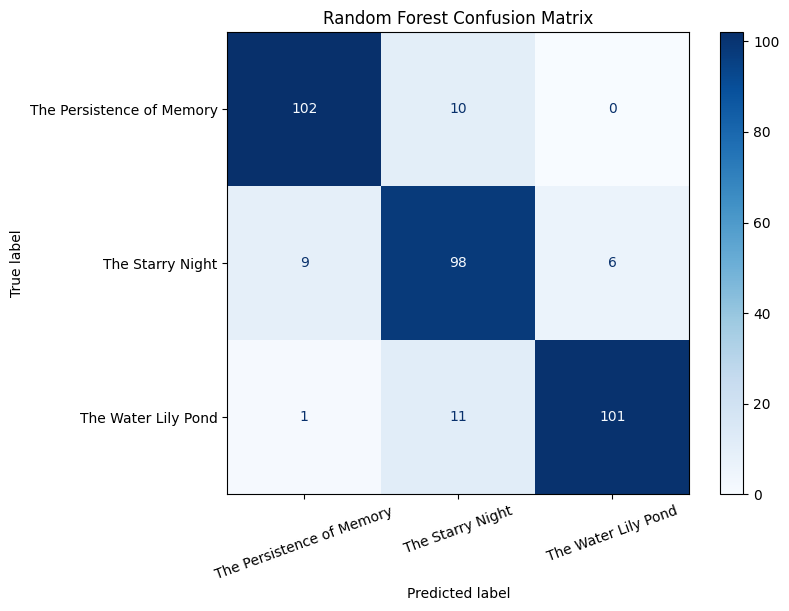

In [31]:
# =========================================================
# 5. Confusion matrix
# =========================================================
labels = sorted(np.unique(y_trainval))

cm = confusion_matrix(y_test, y_test_pred, labels=labels)
cm_df = pd.DataFrame(cm, index=labels, columns=labels)

print("\nConfusion Matrix (rows = true, columns = predicted):")
print(cm_df.to_string())

cm_df.to_csv("artifacts/random_forest_confusion_matrix.csv")

from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)

fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(ax=ax, cmap="Blues", values_format="d")

plt.title("Random Forest Confusion Matrix")
plt.xticks(rotation=20)
plt.show()

In [32]:
# =========================================================
# 6. Save trained model and preprocessing objects
# =========================================================
joblib.dump(best_rf_model, "artifacts/best_random_forest_model.joblib")
joblib.dump(tfidf, "artifacts/tfidf_vectorizer.joblib")
joblib.dump(ohe, "artifacts/onehot_encoder.joblib")

print("\nSaved best Random Forest model and preprocessing objects.")

# =========================================================
# 7. Save summary table
# =========================================================
rf_summary_df = pd.DataFrame([{
    "best_n_estimators": best_rf_params["n_estimators"],
    "best_max_depth": best_rf_params["max_depth"],
    "best_ccp_alpha": best_rf_params["ccp_alpha"],
    "cv_accuracy_mean": best_cv_acc,
    "cv_macro_f1_mean": best_cv_f1,
    "test_accuracy": test_accuracy,
    "test_macro_f1": test_macro_f1
}])

print("\nRandom Forest Summary:")
print(rf_summary_df)

rf_summary_df.to_csv("artifacts/random_forest_summary.csv", index=False)


Saved best Random Forest model and preprocessing objects.

Random Forest Summary:
   best_n_estimators  best_max_depth  best_ccp_alpha  cv_accuracy_mean  \
0                100              20           0.001          0.882043   

   cv_macro_f1_mean  test_accuracy  test_macro_f1  
0           0.88126       0.890533       0.891241  


Learning Curve Table:
   n_train_samples  train_accuracy_mean  train_accuracy_std  cv_accuracy_mean  \
0              107             0.992523            0.010899          0.793738   
1              215             0.984186            0.006961          0.843464   
2              431             0.980510            0.004303          0.865719   
3              646             0.977090            0.002663          0.858295   
4              862             0.974478            0.001641          0.876833   
5             1078             0.970501            0.000909          0.876850   

   cv_accuracy_std  
0         0.047979  
1         0.018571  
2         0.016529  
3         0.015931  
4         0.019382  
5         0.014557  


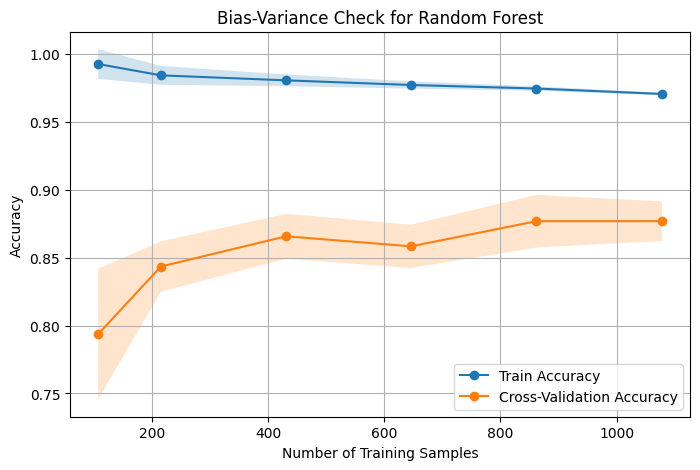

In [33]:
# ============================================
# 8. Bias-Variance Check using learning curves
# ============================================

from sklearn.model_selection import learning_curve, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Define the best Random Forest model using the best hyperparameters found earlier
rf_best_for_curve = RandomForestClassifier(
    n_estimators=best_rf_params["n_estimators"],
    max_depth=best_rf_params["max_depth"],
    ccp_alpha=best_rf_params["ccp_alpha"],
    min_samples_split=2,
    min_samples_leaf=1,
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)

# Use stratified 5-fold cross-validation on the full train+CV set
# This keeps the class balance similar across folds
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Define the training sizes to evaluate
# These are fractions of the full train+CV set
train_sizes = np.array([0.1, 0.2, 0.4, 0.6, 0.8, 1.0])

# Compute the learning curve
# learning_curve returns:
# - train_sizes_abs: actual number of training samples used
# - train_scores: training accuracy for each fold at each size
# - cv_scores: cross-validation accuracy for each fold at each size
train_sizes_abs, train_scores, cv_scores = learning_curve(
    estimator=rf_best_for_curve,
    X=X_trainval,
    y=y_trainval,
    train_sizes=train_sizes,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1,
    shuffle=True,
    random_state=42
)

# Compute mean accuracy across folds
train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)

cv_mean = cv_scores.mean(axis=1)
cv_std = cv_scores.std(axis=1)

# Put results into a clean table
learning_curve_df = pd.DataFrame({
    "n_train_samples": train_sizes_abs,
    "train_accuracy_mean": train_mean,
    "train_accuracy_std": train_std,
    "cv_accuracy_mean": cv_mean,
    "cv_accuracy_std": cv_std
})

print("Learning Curve Table:")
print(learning_curve_df)

# Save the table
learning_curve_df.to_csv("artifacts/random_forest_learning_curve.csv", index=False)

# Plot training accuracy and cross-validation accuracy
plt.figure(figsize=(8, 5))

plt.plot(
    train_sizes_abs,
    train_mean,
    marker="o",
    label="Train Accuracy"
)

plt.plot(
    train_sizes_abs,
    cv_mean,
    marker="o",
    label="Cross-Validation Accuracy"
)

# Optional: show variation across folds
plt.fill_between(
    train_sizes_abs,
    train_mean - train_std,
    train_mean + train_std,
    alpha=0.2
)

plt.fill_between(
    train_sizes_abs,
    cv_mean - cv_std,
    cv_mean + cv_std,
    alpha=0.2
)

plt.xlabel("Number of Training Samples")
plt.ylabel("Accuracy")
plt.title("Bias-Variance Check for Random Forest")
plt.legend()
plt.grid(True)
plt.show()

Number of plotted feature names: 588
Number of model input features:  588


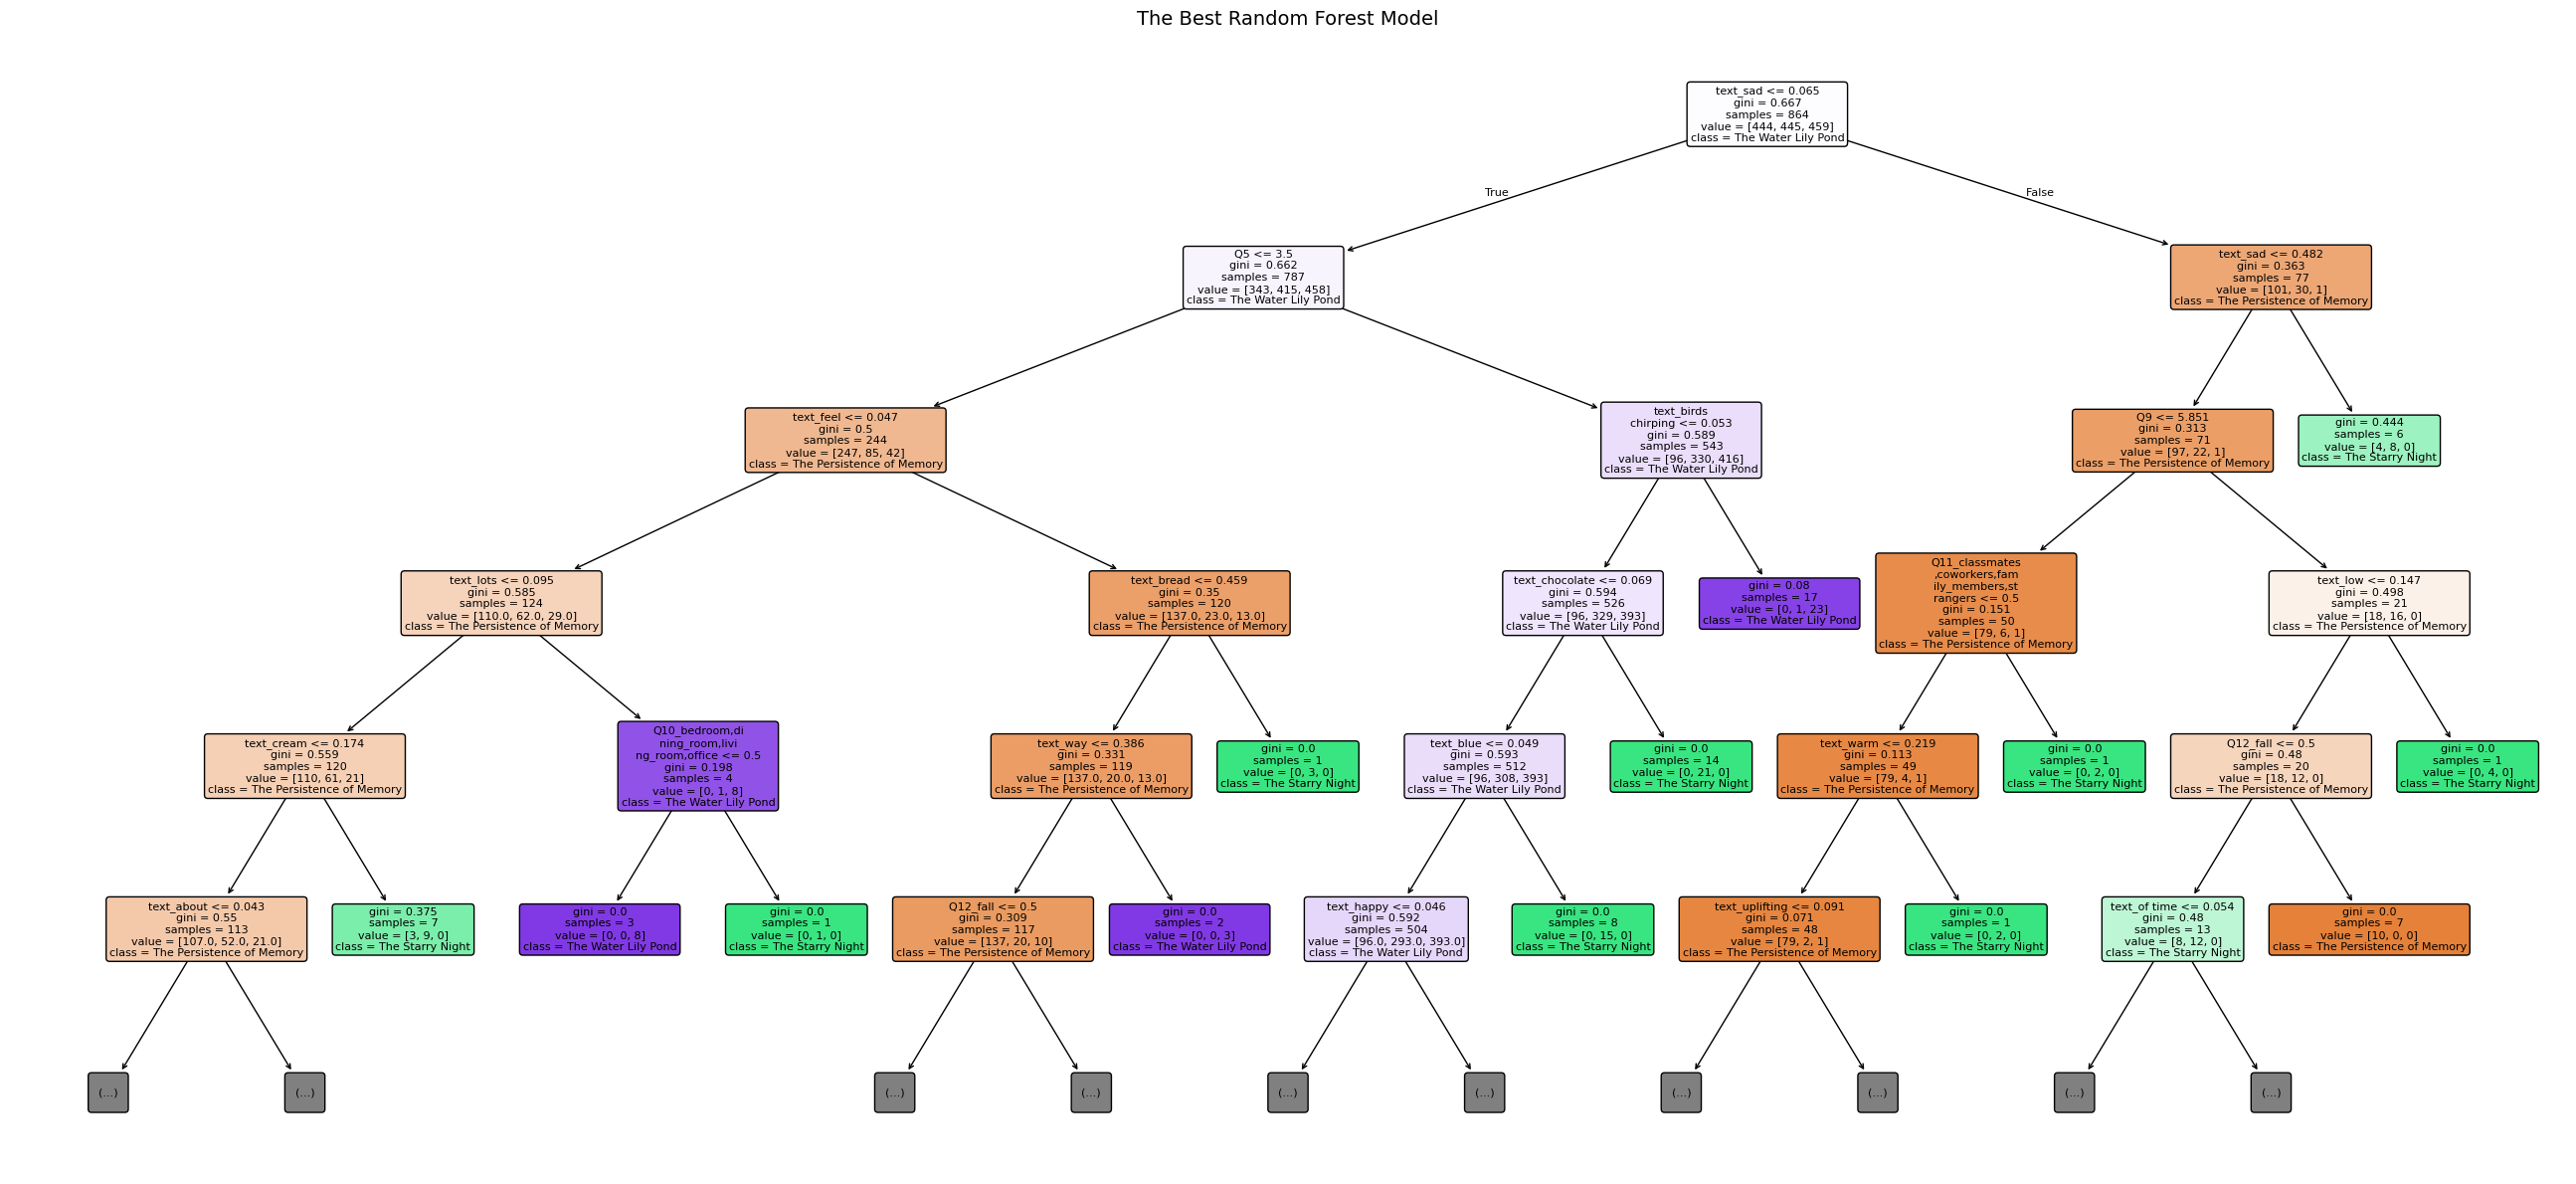

In [34]:
import matplotlib.pyplot as plt
from sklearn import tree
import textwrap
rename_map = {
    # target / id
    "Painting": "painting",
    "unique_id": "unique_id",

    # numeric columns
    "On a scale of 1–10, how intense is the emotion conveyed by the artwork?": "Q1",
    "How many prominent colours do you notice in this painting?": "Q7",
    "How many objects caught your eye in the painting?": "Q8",

    # likert columns
    "This art piece makes me feel sombre.": "Q3",
    "This art piece makes me feel content.": "Q4",
    "This art piece makes me feel calm.": "Q5",
    "This art piece makes me feel uneasy.": "Q6",

    # money column
    "How much (in Canadian dollars) would you be willing to pay for this painting?": "Q9",

    # multi-select columns
    "If you could purchase this painting, which room would you put that painting in?": "Q10",
    "If you could view this art in person, who would you want to view it with?": "Q11",
    "What season does this art piece remind you of?": "Q12",

    # text columns
    "Describe how this painting makes you feel.": "Q2",
    "If this painting was a food, what would be?": "Q13",
    "Imagine a soundtrack for this painting. Describe that soundtrack without naming any objects in the painting.": "Q14",
}

base_numeric_cols = numeric_cols + likert_cols
numeric_feature_names = [rename_map.get(col, col) for col in base_numeric_cols]

# one-hot encoded categorical names
try:
    cat_feature_names_raw = ohe.get_feature_names_out(multi_select_cols)
except AttributeError:
    cat_feature_names_raw = ohe.get_feature_names(multi_select_cols)

def shorten_feature_name(name):
    name = str(name)
    for old, new in rename_map.items():
        name = name.replace(old, new)
    name = name.replace(" ", "_")
    return name

cat_feature_names = [shorten_feature_name(name) for name in cat_feature_names_raw]

# TF-IDF features come from combined_text, so these are token-level features
text_feature_names = [f"text_{tok}" for tok in tfidf.get_feature_names_out()]

# final feature names in exact training order
final_feature_names = numeric_feature_names + cat_feature_names + text_feature_names

print("Number of plotted feature names:", len(final_feature_names))
print("Number of model input features: ", X_trainval.shape[1])

assert len(final_feature_names) == X_trainval.shape[1], \
    "Feature-name count does not match model input dimension."

wrapped_feature_names = [
    "\n".join(textwrap.wrap(name, width=14)) for name in final_feature_names
]

# -------------------------------------------------
# Plot one tree
# -------------------------------------------------
one_tree = best_rf_model.estimators_[0]

plt.figure(figsize=(26, 12))
tree.plot_tree(
    one_tree,
    feature_names=wrapped_feature_names,
    class_names=[str(c) for c in best_rf_model.classes_],
    filled=True,
    rounded=True,
    fontsize=8,
    max_depth=5
)
plt.title("The Best Random Forest Model", fontsize=14)
plt.tight_layout()
plt.show()

In [38]:
plt.figure(figsize=(80, 30), dpi=200)
tree.plot_tree(
    one_tree,
    feature_names=wrapped_feature_names,
    class_names=[str(c) for c in best_rf_model.classes_],
    filled=True,
    rounded=True,
    fontsize=8,
)
plt.title("The Best Random Forest Model", fontsize=14)
plt.tight_layout()
plt.show()